In [45]:
import pandas as pd

# Check structure of S3 first
s3 = pd.read_excel('./results/proteomics/CPTAC_S3_tumor_NAT.xlsx', sheet_name=None)
print("Sheets in S3:", list(s3.keys()))

Sheets in S3: ['Description', 'Table S3A', 'Table S3B', 'Table S3C', 'Table S3D', 'Table S3E', 'Table S3F', 'Table S3G', 'Table S3H']


In [46]:
# Check description sheet first to understand what each table contains
desc = s3['Description']
print(desc.to_string())

                                   Table S3. Tumor-NAT Comparisons Reveal SCLC-associated Proteomic Events, Related to Figure 3 and S3.
0                                                            Table S3A. Differential protein expression between tumors and paired NATs.
1                                     Table S3B. Over-representation analysis for 2-fold upregulated and 2-fold downregulated proteins.
2  Table S3C. Differential protein expression between tumors and paired NATs in combined SCLC (CSCLC) and pure SCLC samples separately.
3                                                        Table S3D. Differential phosphosite expression between tumors and paired NATs.
4                  Table S3E. Over-representation analysis for proteins with a phosphosite 2-fold upregulated and 2-fold downregulated.
5             Table S3F. Differential phosphosites analyses between tumors and paired NATs with their corresponding protein expression.
6                                               

In [49]:
s3a = s3['Table S3A']
print(s3a.shape)
print(s3a.columns.tolist())
print(s3a.head())

(7010, 5)
['Gene.symbol', 'P.value', 'FDR', 'Log2.median.foldchange', 'SCLC.associated.proteins']
  Gene.symbol       P.value           FDR  Log2.median.foldchange  \
0       STMN2  4.151979e-20  3.705489e-19                3.208776   
1       STMN1  4.151979e-20  3.705489e-19                2.649582   
2       HMGB3  5.290913e-20  3.705489e-19                2.632961   
3       UCHL1  1.119900e-19  5.111004e-19                2.516165   
4        H1-5  7.302000e-20  3.949616e-19                2.337677   

   SCLC.associated.proteins  
0                       1.0  
1                       1.0  
2                       1.0  
3                       1.0  
4                       1.0  


In [51]:
import pandas as pd

# Define all hub genes by cluster
cluster1_hubs = ['KIF11', 'KIF2C', 'BUB1', 'ASPM', 'BUB1B', 'CDK1', 'CCNA2', 
                 'TPX2', 'DLGAP5', 'CENPF', 'EXO1', 'BRCA1', 'CHEK1', 
                 'TYMS', 'PLK1', 'CDC20', 'AURKB', 'TOP2A']

cluster2_hubs = ['IL6', 'TLR4', 'TLR2', 'CCL2', 'CASP1', 'IL18', 
                 'TNFRSF1A', 'MYD88', 'IL1R1', 'TLR3', 'CD36', 'PTGS2']

cluster3_hubs = ['FOS', 'EGR1', 'EGR2', 'ATF3', 'MYC', 'FOSB', 'JUNB', 
                 'DUSP1', 'ZFP36', 'IER2', 'CEBPB', 'HDAC2', 'EZH2', 
                 'CEBPD', 'CCND1']

cluster4_hubs = ['CD44', 'ITGA3', 'ITGA8', 'ITGB5', 'LAMA2']

for cluster_name, hub_list in [('Cluster 1 (Cell Cycle)', cluster1_hubs),
                                ('Cluster 2 (Immune/Cytokine)', cluster2_hubs),
                                ('Cluster 3 (TF/Epigenetic)', cluster3_hubs),
                                ('Cluster 4 (ECM/Adhesion)', cluster4_hubs)]:
    matches = s3a[s3a['Gene.symbol'].isin(hub_list)]
    print(f"\n{cluster_name}:")
    print(f"Found: {len(matches)}/{len(hub_list)} genes")
    print(matches[['Gene.symbol', 'FDR', 'Log2.median.foldchange', 'SCLC.associated.proteins']].to_string())


Cluster 1 (Cell Cycle):
Found: 13/18 genes
    Gene.symbol           FDR  Log2.median.foldchange  SCLC.associated.proteins
6         TOP2A  3.705489e-19                2.143770                       1.0
108       AURKB  4.167855e-19                1.424088                       NaN
111       CCNA2  1.304314e-18                1.412091                       NaN
199       KIF11  3.705489e-19                1.282356                       NaN
202        CDK1  3.705489e-19                1.279475                       NaN
235      DLGAP5  3.834966e-19                1.240869                       NaN
247        TPX2  3.705489e-19                1.229897                       NaN
328       KIF2C  3.949616e-19                1.150431                       NaN
365       CENPF  3.705489e-19                1.109657                       NaN
369        TYMS  3.098926e-18                1.105585                       NaN
395       CHEK1  3.617425e-17                1.079730                       

In [1]:
import pandas as pd

s4 = pd.read_excel('./results/proteomics/CPTAC_S4_survival.xlsx', sheet_name=None)
print("Sheets in S4:", list(s4.keys()))

Sheets in S4: ['Description', 'Table S4A', 'Table S4B', 'Table S4C', 'Table S4D', 'Table S4E']


In [2]:
desc = s4['Description']
print(desc.to_string())

               Table S4. Functional Analyses of Identified Proteins Associated with Survival, Related to Figure 4 and S4.
0                                                              Table S4A. The list of 16 candidate prognostic biomarkers.
1                          Table S4B. Relationship between clinicopathologic characteristics and HMGB3/CASP10 expression.
2                Table S4C. Univariable and multivariable analyses of factors associated with survival in TU-SCLC cohort.
3  Table S4D. Relationship between clinicopathologic characteristics and immunostaining markers in the validation cohort.
4         Table S4E. Univariable and multivariable analyses of factors associated with survival in the validation cohort.


In [3]:
s4a = s4['Table S4A']
print(s4a.shape)
print(s4a.columns.tolist())
print(s4a.head())

(16, 10)
['Gene.symbol', 'Protein.P.value.T.vs.NAT', 'Protein.FDR.T.vs.NAT', 'Protein.log2.median.foldchange', 'RNA.P.value.T.vs.NAT', 'RNA.FDR.T.vs.NAT', 'RNA.log2.median.foldchange', 'mRNA.Protein.correlation', 'Log.rank.P.value', 'Hazard.ratio']
  Gene.symbol  Protein.P.value.T.vs.NAT  Protein.FDR.T.vs.NAT  \
0       HMGB3              5.290913e-20          3.705489e-19   
1       ACYP1              9.800223e-20          4.673439e-19   
2       KDM1A              4.151979e-20          3.705489e-19   
3       FKBP3              4.265470e-20          3.705489e-19   
4        MTA1              4.624667e-20          3.705489e-19   

   Protein.log2.median.foldchange  RNA.P.value.T.vs.NAT  RNA.FDR.T.vs.NAT  \
0                        2.632961          2.770104e-19      4.778195e-18   
1                        1.544719          4.166574e-19      4.778195e-18   
2                        1.196364          2.770104e-19      4.778195e-18   
3                        1.152799          2.770104e

In [7]:
all_hub_genes = [
    # Cluster 1 - Cell Cycle (MCC + Betweenness, deduplicated)
    'KIF11', 'KIF2C', 'BUB1', 'ASPM', 'BUB1B', 'CDK1', 'CCNA2',
    'TPX2', 'DLGAP5', 'CENPF', 'EXO1', 'BRCA1', 'CHEK1',
    'TYMS', 'PLK1', 'CDC20', 'AURKB', 'TOP2A',
    # Cluster 2 - Immune/Cytokine (MCC + Betweenness, deduplicated)
    'IL6', 'TLR4', 'TLR2', 'CCL2', 'CASP1', 'IL18',
    'TNFRSF1A', 'MYD88', 'IL1R1', 'TLR3', 'CD36', 'PTGS2',
    # Cluster 3 - TF/Epigenetic (MCC + Betweenness, deduplicated)
    'FOS', 'EGR1', 'EGR2', 'ATF3', 'MYC', 'FOSB', 'JUNB',
    'DUSP1', 'ZFP36', 'IER2', 'CEBPB', 'HDAC2', 'EZH2', 'CEBPD', 'CCND1',
    # Cluster 4 - ECM/Adhesion
    'CD44', 'ITGA3', 'ITGA8', 'ITGB5', 'LAMA2'
]

s4a_hits = s4['Table S4A'][s4['Table S4A']['Gene.symbol'].isin(all_hub_genes)]
print(f"Hub genes found in S4A: {len(s4a_hits)}")
print(s4a_hits[['Gene.symbol', 'Protein.log2.median.foldchange',
                 'Log.rank.P.value', 'Hazard.ratio']].to_string())

Hub genes found in S4A: 0
Empty DataFrame
Columns: [Gene.symbol, Protein.log2.median.foldchange, Log.rank.P.value, Hazard.ratio]
Index: []


In [9]:
s4c = s4['Table S4C']
print(s4c.shape)
print(s4c.columns.tolist())
print(s4c.head(10))

(34, 8)
['Variables', 'Unnamed: 1', 'Unvariate analysis', 'Unnamed: 3', 'Multivariate analysis', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7']
  Variables         Unnamed: 1    Unvariate analysis Unnamed: 3  \
0       NaN                NaN                   NaN        NaN   
1       NaN                NaN  Hazard Ratio (95%CI)          P   
2       Age                NaN   1.050 (1.015-1.085)     0.0044   
3    Gender             Female             Reference        NaN   
4       NaN               Male   1.554 (0.663-3.646)      0.311   
5   Smoking                 no             Reference        NaN   
6       NaN            unknown   2.159 (0.794-5.870)      0.132   
7       NaN                yes   0.829 (0.348-1.971)      0.671   
8   Surgery  limited lobectomy             Reference        NaN   
9       NaN          lobectomy   0.223 (0.068-0.729)      0.013   

  Multivariate analysis Unnamed: 5            Unnamed: 6 Unnamed: 7  
0                 HMGB3        NaN                CAS

In [11]:
s4e = s4['Table S4E']
print(s4e.shape)
print(s4e.columns.tolist())
print(s4e.head(10))

(34, 8)
['Variables', 'Unnamed: 1', 'Unvariate analysis', 'Unnamed: 3', 'Multivariate analysis', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7']
  Variables         Unnamed: 1    Unvariate analysis Unnamed: 3  \
0       NaN                NaN                   NaN        NaN   
1       NaN                NaN  Hazard Ratio (95%CI)          P   
2       Age                NaN   1.005 (0.951-1.063)      0.854   
3    Gender             Female             Reference        NaN   
4       NaN               Male   1.789 (0.425-7.539)      0.428   
5   Smoking         no/unknown             Reference        NaN   
6       NaN                yes   1.310 (0.614-2.799)      0.485   
7   Surgery  limited lobectomy             Reference        NaN   
8       NaN          lobectomy   1.005 (0.238-4.250)      0.994   
9       NaN      pneumonectomy   0.661 (0.060-7.299)      0.736   

  Multivariate analysis Unnamed: 5            Unnamed: 6 Unnamed: 7  
0                 HMGB3        NaN                CAS

In [17]:
!pip install pyxlsb==1.0.10

In [13]:
s1 = pd.read_excel('./results/proteomics/CPTAC_S1_clinical.xlsb', 
                   sheet_name=None, engine='pyxlsb')
print("Sheets in S1:", list(s1.keys()))

Sheets in S1: ['Description', 'Table S1A', 'Table S1B', 'Table S1C', 'Table S1D', 'Table S1E', 'Table S1F', 'Table S1G', 'Table S1H']


In [15]:
desc = s1['Description']
print(desc.to_string())

                                                                                                                                      Table S1. Clinical Information and Multi-omics Data in TU-SCLC Cohort, Related to Figure 1 and S1.
0                                                                                                      Table S1A. Clinical Information. Clinical characteristics of the TU-SCLC cohort and samples included in the multi-omics analysis.
1                                                                                                                       Table S1B. Somatic Mutations. List of somatic mutations (SNVs & INDELs) identified in the TU-SCLC cohort by WES.
2                                                                                                                        Table S1C. Copy Number Data. Log2 transformed gene-level copy number coverage ratios obtained from CopyWrite R.
3                                                                   

In [17]:
s1a = s1['Table S1A']
print(s1a.shape)
print(s1a.columns.tolist())
print(s1a.head())

(112, 22)
['Sample.ID', 'Gender', 'Age', 'Weight', 'Height', 'Surgery', 'Tumor.site', 'Histologic.type', 'NSCLC.Component.of.CSCLC', 'Smoking', 'Number.of.tumors', 'Tumor.size.(cm)', 'T', 'N', 'M', 'TNM.Stage', 'VALSG.stage', 'Pleural.invasion', 'Vessel.invasion', 'Nerve.invasion', 'Status.', 'Survial.(months)']
   Sample.ID Gender  Age  Weight  Height            Surgery        Tumor.site  \
0     120111      M   66    75.0     163      pneumonectomy   left upper lobe   
1     120163      F   46    55.0     161      pneumonectomy   left upper lobe   
2     120165      M   68    60.0     168          lobectomy  right upper lobe   
3     120285      F   59    55.0     154  limited lobectomy  right upper lobe   
4     130020      M   69    62.0     165          lobectomy   left upper lobe   

                   Histologic.type NSCLC.Component.of.CSCLC Smoking  ...   T  \
0  combined small cell lung cancer          squamous cancer      no  ...   3   
1           small cell lung cancer     

In [19]:
print(s1a[['Status.', 'Survial.(months)']].isnull().sum())
print(s1a['Status.'].value_counts())

Status.             0
Survial.(months)    4
dtype: int64
Status.
dead     60
alive    52
Name: count, dtype: int64


In [21]:
consensus = pd.read_csv('./results/DEG/consensus_DEGs.csv')
print(consensus.columns.tolist())
print(consensus.head())

['Gene', 'direction']
      Gene direction
0   DLGAP5        Up
1     CDT1        Up
2  SLC18A1        Up
3   TMEM97        Up
4  IGFBPL1        Up


In [23]:
print(consensus[consensus['Gene'].isin(['EZH2', 'HDAC2'])]) # to check if they are actually up regulated or down

      Gene direction
88    EZH2        Up
366  HDAC2        Up


In [25]:
all_hub_genes = [
    # Cluster 1
    'KIF11', 'KIF2C', 'BUB1', 'ASPM', 'BUB1B', 'CDK1', 'CCNA2',
    'TPX2', 'DLGAP5', 'CENPF', 'EXO1', 'BRCA1', 'CHEK1',
    'TYMS', 'PLK1', 'CDC20', 'AURKB', 'TOP2A',
    # Cluster 2
    'IL6', 'TLR4', 'TLR2', 'CCL2', 'CASP1', 'IL18',
    'TNFRSF1A', 'MYD88', 'IL1R1', 'TLR3', 'CD36', 'PTGS2',
    # Cluster 3
    'FOS', 'EGR1', 'EGR2', 'ATF3', 'MYC', 'FOSB', 'JUNB',
    'DUSP1', 'ZFP36', 'IER2', 'CEBPB', 'HDAC2', 'EZH2', 'CEBPD', 'CCND1',
    # Cluster 4
    'CD44', 'ITGA3', 'ITGA8', 'ITGB5', 'LAMA2'
]

hub_directions = consensus[consensus['Gene'].isin(all_hub_genes)][['Gene', 'direction']]
print(f"Hub genes found in consensus: {len(hub_directions)}")
print(hub_directions.to_string())

Hub genes found in consensus: 50
          Gene direction
0       DLGAP5        Up
19       CENPF        Up
51        ASPM        Up
54       CDC20        Up
88        EZH2        Up
180       BUB1        Up
193      AURKB        Up
213       CDK1        Up
229       TPX2        Up
237      BRCA1        Up
261      KIF2C        Up
292      KIF11        Up
304       PLK1        Up
326      CHEK1        Up
346      TOP2A        Up
366      HDAC2        Up
415      BUB1B        Up
435      CCNA2        Up
445       EXO1        Up
465       TYMS        Up
545      CCND1      Down
564       IL18      Down
595       FOSB      Down
701       TLR3      Down
705      IL1R1      Down
781      DUSP1      Down
799        MYC      Down
813      ITGB5      Down
817      CASP1      Down
833       ATF3      Down
865      CEBPB      Down
869       JUNB      Down
896      CEBPD      Down
909      ITGA8      Down
932      LAMA2      Down
934        FOS      Down
951   TNFRSF1A      Down
1006      CD36   

In [41]:
cluster_map = {
    'Cluster1': ['KIF11', 'KIF2C', 'BUB1', 'ASPM', 'BUB1B', 'CDK1', 'CCNA2',
                 'TPX2', 'DLGAP5', 'CENPF', 'EXO1', 'BRCA1', 'CHEK1',
                 'TYMS', 'PLK1', 'CDC20', 'AURKB', 'TOP2A'],
    'Cluster2': ['IL6', 'TLR4', 'TLR2', 'CCL2', 'CASP1', 'IL18',
                 'TNFRSF1A', 'MYD88', 'IL1R1', 'TLR3', 'CD36', 'PTGS2'],
    'Cluster3': ['FOS', 'EGR1', 'EGR2', 'ATF3', 'MYC', 'FOSB', 'JUNB',
                 'DUSP1', 'ZFP36', 'IER2', 'CEBPB', 'HDAC2', 'EZH2', 'CEBPD', 'CCND1'],
    'Cluster4': ['CD44', 'ITGA3', 'ITGA8', 'ITGB5', 'LAMA2']
}

for cluster, genes in cluster_map.items():
    subset = hub_directions[hub_directions['Gene'].isin(genes)]
    counts = subset['direction'].value_counts()
    print(f"\n{cluster}:")
    print(f"  Up: {counts.get('Up', 0)}, Down: {counts.get('Down', 0)}")
    print(subset.to_string())


Cluster1:
  Up: 18, Down: 0
       Gene direction
0    DLGAP5        Up
19    CENPF        Up
51     ASPM        Up
54    CDC20        Up
180    BUB1        Up
193   AURKB        Up
213    CDK1        Up
229    TPX2        Up
237   BRCA1        Up
261   KIF2C        Up
292   KIF11        Up
304    PLK1        Up
326   CHEK1        Up
346   TOP2A        Up
415   BUB1B        Up
435   CCNA2        Up
445    EXO1        Up
465    TYMS        Up

Cluster2:
  Up: 0, Down: 12
          Gene direction
564       IL18      Down
701       TLR3      Down
705      IL1R1      Down
817      CASP1      Down
951   TNFRSF1A      Down
1006      CD36      Down
1009     PTGS2      Down
1076      CCL2      Down
1125       IL6      Down
1202     MYD88      Down
1228      TLR2      Down
1276      TLR4      Down

Cluster3:
  Up: 2, Down: 13
       Gene direction
88     EZH2        Up
366   HDAC2        Up
545   CCND1      Down
595    FOSB      Down
781   DUSP1      Down
799     MYC      Down
833    ATF3     

In [33]:
s1e = s1['Table S1E']
print(s1e.shape)
print(s1e.columns.tolist()[:10])  # just first 10 columns, likely 112 patients so will be wide
print(s1e.head())

(9559, 225)
['Protein/Sample.ID', 'T120111', 'T120163', 'T120165', 'T120285', 'T130020', 'T130023', 'T130157', 'T130199', 'T130214']
  Protein/Sample.ID   T120111   T120163   T120165   T120285   T130020  \
0              A1BG -1.225663 -0.557110 -0.776922  1.355804  0.288214   
1               A2M -1.906790 -0.712272 -0.957522  0.240597 -1.236657   
2              AAAS  0.326234  0.236818  1.370204  0.121569  0.491775   
3              AACS  1.661656 -0.470229 -1.487841 -0.172675 -0.201740   
4             AADAC -1.325155 -0.489851 -1.043829       NaN       NaN   

    T130023   T130157   T130199   T130214  ...   N182084   N182097   N190069  \
0 -0.824387 -0.282311 -0.045269  0.034903  ...  1.222208  1.369664  0.735778   
1 -1.330127 -1.249055 -0.504011 -0.975544  ...  1.393407  2.501910  0.516354   
2 -0.217533  1.025396  0.563029  0.797087  ...  0.066469  0.093294 -0.400631   
3  0.842422  1.187365  2.013775  1.020655  ... -0.539325 -0.553028 -0.891434   
4 -1.551860       NaN -0.150

In [29]:
# Only genes validated in S3A proteomics
s3a_validated = {
    'Cluster1': ['TOP2A', 'AURKB', 'CCNA2', 'KIF11', 'CDK1', 'DLGAP5', 
                 'TPX2', 'KIF2C', 'CENPF', 'TYMS', 'CHEK1', 'PLK1', 'BUB1'],
    'Cluster2': ['MYD88', 'IL18', 'CASP1', 'TLR2', 'TLR3', 'CD36'],
    'Cluster3': ['HDAC2', 'EZH2', 'CEBPB'],
    'Cluster4': ['LAMA2', 'ITGB5', 'CD44', 'ITGA3', 'ITGA8']
}

all_validated = [g for genes in s3a_validated.values() for g in genes]

s1e_hits = s1e[s1e['Protein/Sample.ID'].isin(all_validated)]['Protein/Sample.ID'].tolist()
print(f"Validated hub genes found in S1E: {len(s1e_hits)}/{len(all_validated)}")
print(s1e_hits)

Validated hub genes found in S1E: 27/27
['AURKB', 'BUB1', 'CASP1', 'CCNA2', 'CD36', 'CD44', 'CDK1', 'CEBPB', 'CENPF', 'CHEK1', 'DLGAP5', 'EZH2', 'HDAC2', 'IL18', 'ITGA3', 'ITGA8', 'ITGB5', 'KIF11', 'KIF2C', 'LAMA2', 'MYD88', 'PLK1', 'TLR2', 'TLR3', 'TOP2A', 'TPX2', 'TYMS']


In [41]:
import matplotlib.pyplot as plt

s1e_validated = s1e[s1e['Protein/Sample.ID'].isin(all_validated)].set_index('Protein/Sample.ID')

# Keep only tumor samples (columns starting with T)
tumor_cols = [col for col in s1e_validated.columns if col.startswith('T')]
s1e_tumor = s1e_validated[tumor_cols]

print(f"Tumor samples: {len(tumor_cols)}")
print(f"\nMedian expression per gene:")
print(s1e_tumor.median(axis=1).to_string())

Tumor samples: 112

Median expression per gene:
Protein/Sample.ID
AURKB     0.388388
BUB1      0.255905
CASP1    -0.487982
CCNA2     0.375961
CD36     -1.791739
CD44     -0.634845
CDK1      0.361214
CEBPB    -0.246307
CENPF     0.250249
CHEK1     0.230576
DLGAP5    0.289344
EZH2      0.442910
HDAC2     0.550241
IL18     -0.272409
ITGA3    -1.070236
ITGA8    -1.187966
ITGB5    -0.426298
KIF11     0.365870
KIF2C     0.279035
LAMA2    -0.365795
MYD88     0.137422
PLK1      0.303690
TLR2     -0.533060
TLR3     -0.817099
TOP2A     0.471010
TPX2      0.322945
TYMS      0.285790


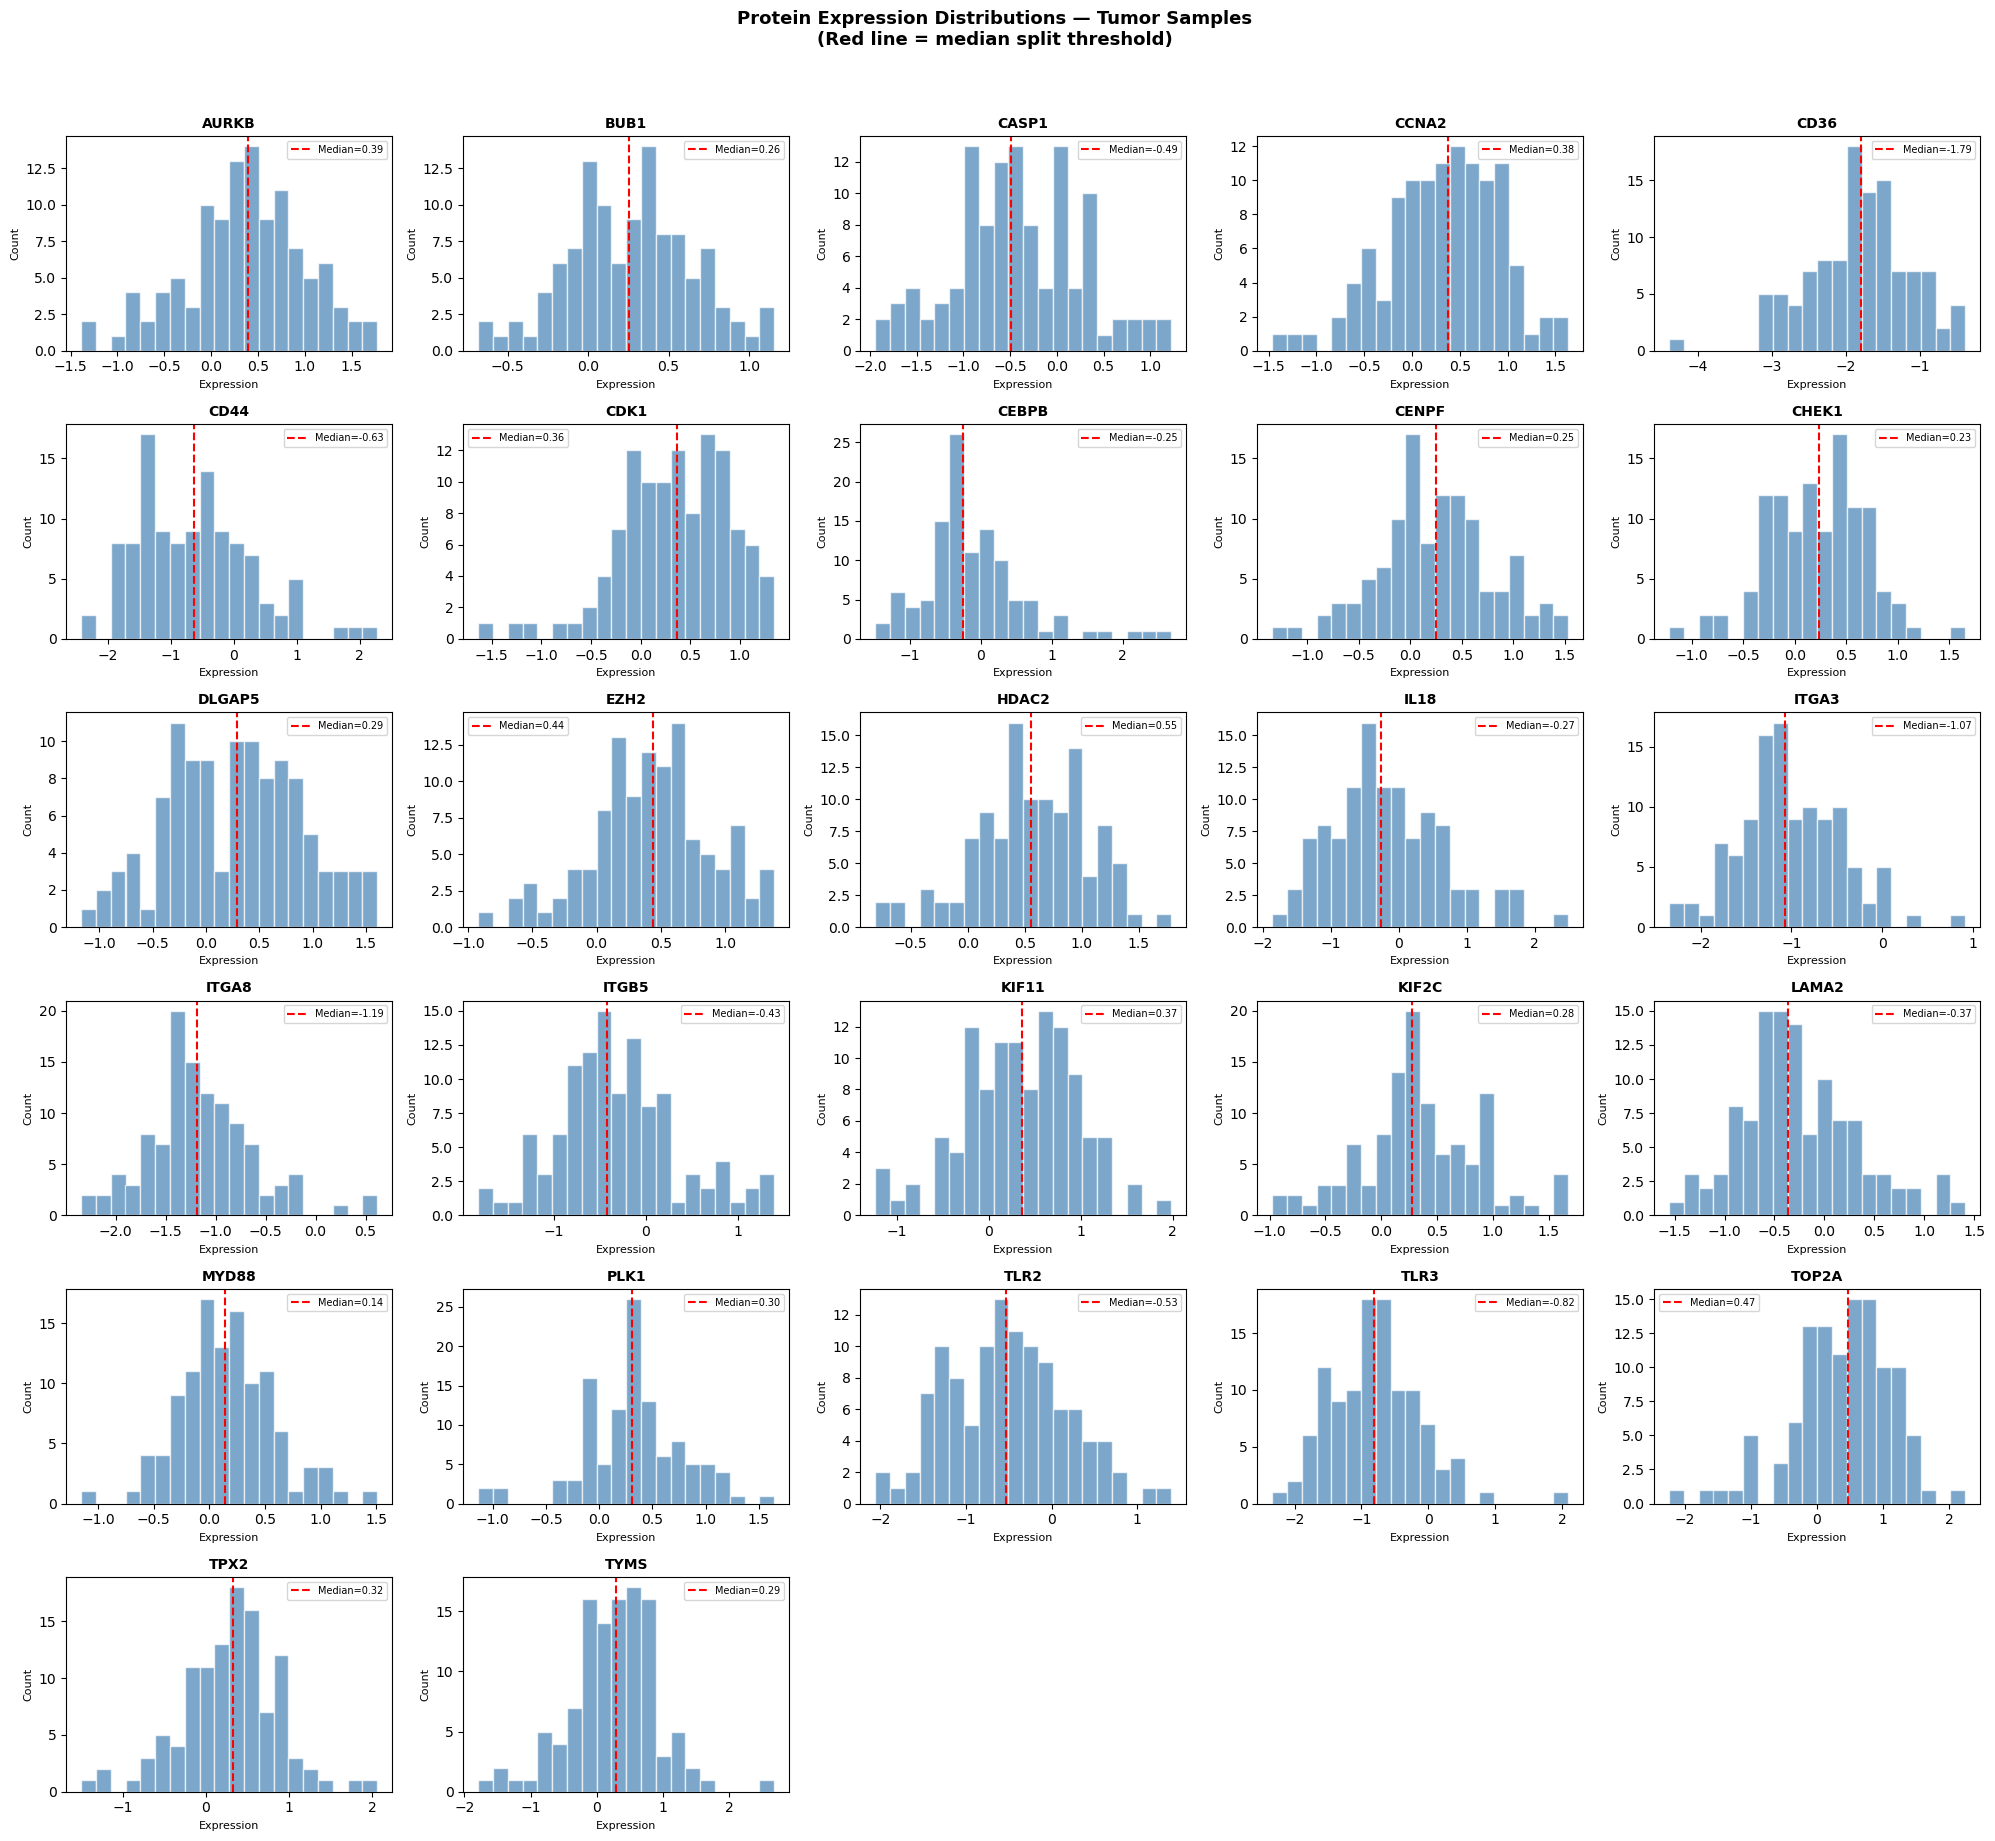

In [43]:
fig, axes = plt.subplots(6, 5, figsize=(20, 18))
axes = axes.flatten()

for i, gene in enumerate(sorted(s1e_tumor.index)):
    values = s1e_tumor.loc[gene].dropna()
    median_val = values.median()
    axes[i].hist(values, bins=20, color='steelblue', alpha=0.7, edgecolor='white')
    axes[i].axvline(median_val, color='red', linestyle='--', linewidth=1.5, label=f'Median={median_val:.2f}')
    axes[i].set_title(gene, fontsize=10, fontweight='bold')
    axes[i].set_xlabel('Expression', fontsize=8)
    axes[i].set_ylabel('Count', fontsize=8)
    axes[i].legend(fontsize=7)

# Hide unused subplots
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Protein Expression Distributions — Tumor Samples\n(Red line = median split threshold)', 
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.savefig('./figures/expression_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

In [45]:
missing_per_gene = s1e_tumor.isnull().sum(axis=1)
missing_pct = (missing_per_gene / len(tumor_cols) * 100).round(2)

missing_df = pd.DataFrame({
    'missing_count': missing_per_gene,
    'missing_pct': missing_pct
}).loc[s1e_tumor.index]

print(missing_df.sort_values('missing_pct', ascending=False).to_string())

                   missing_count  missing_pct
Protein/Sample.ID                            
AURKB                          0          0.0
ITGA3                          0          0.0
TPX2                           0          0.0
TOP2A                          0          0.0
TLR3                           0          0.0
TLR2                           0          0.0
PLK1                           0          0.0
MYD88                          0          0.0
LAMA2                          0          0.0
KIF2C                          0          0.0
KIF11                          0          0.0
ITGB5                          0          0.0
ITGA8                          0          0.0
IL18                           0          0.0
BUB1                           0          0.0
HDAC2                          0          0.0
EZH2                           0          0.0
DLGAP5                         0          0.0
CHEK1                          0          0.0
CENPF                          0  

In [71]:
!pip install diptest==0.10.0

In [47]:
import diptest

dip_results = []
for gene in s1e_tumor.index:
    values = s1e_tumor.loc[gene].dropna().values
    dip, pval = diptest.diptest(values)
    dip_results.append({
        'Gene': gene,
        'Dip_statistic': round(dip, 4),
        'P_value': round(pval, 4),
        'Unimodal': 'Yes' if pval >= 0.05 else 'No — flag'
    })

dip_df = pd.DataFrame(dip_results).sort_values('P_value')
print(dip_df.to_string())

      Gene  Dip_statistic  P_value Unimodal
18   KIF2C         0.0419   0.1648      Yes
21    PLK1         0.0378   0.2952      Yes
10  DLGAP5         0.0358   0.3851      Yes
8    CENPF         0.0354   0.4047      Yes
15   ITGA8         0.0333   0.5168      Yes
26    TYMS         0.0324   0.5668      Yes
1     BUB1         0.0311   0.6418      Yes
5     CD44         0.0310   0.6485      Yes
11    EZH2         0.0299   0.7123      Yes
13    IL18         0.0297   0.7195      Yes
2    CASP1         0.0285   0.7875      Yes
6     CDK1         0.0269   0.8583      Yes
3    CCNA2         0.0266   0.8703      Yes
17   KIF11         0.0263   0.8845      Yes
23    TLR3         0.0256   0.9121      Yes
25    TPX2         0.0250   0.9291      Yes
24   TOP2A         0.0244   0.9466      Yes
19   LAMA2         0.0243   0.9501      Yes
14   ITGA3         0.0242   0.9524      Yes
12   HDAC2         0.0241   0.9539      Yes
20   MYD88         0.0238   0.9594      Yes
9    CHEK1         0.0230   0.97

In [79]:
!pip install lifelines==0.30.3

In [49]:
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

# Prepare survival data from S1A
# Drop patients with missing survival time
survival_df = s1a[['Sample.ID', 'Status.', 'Survial.(months)']].dropna()

# Convert status to binary — 1=dead, 0=alive/censored
survival_df = survival_df.copy()
survival_df['event'] = (survival_df['Status.'] == 'dead').astype(int)
survival_df = survival_df.rename(columns={'Survial.(months)': 'time'})

print(f"Patients after dropping missing survival time: {len(survival_df)}")
print(f"Events (dead): {survival_df['event'].sum()}")
print(f"Censored (alive): {(survival_df['event'] == 0).sum()}")
print(survival_df.head())

Patients after dropping missing survival time: 108
Events (dead): 56
Censored (alive): 52
   Sample.ID Status.       time  event
0     120111    dead  26.033333      1
2     120165   alive       97.6      0
3     120285    dead  18.833333      1
4     130020   alive  89.433333      0
6     130157    dead   6.866667      1


In [51]:
# Transpose S1E tumor data so patients are rows, genes are columns
expr_T = s1e_tumor.T
expr_T.index = expr_T.index.str.replace('T', '', n=1)  # remove T prefix to match Sample.ID
expr_T.index = expr_T.index.astype(str)
survival_df['Sample.ID'] = survival_df['Sample.ID'].astype(str)

# Merge on Sample.ID
merged_df = survival_df.merge(expr_T, left_on='Sample.ID', right_index=True, how='inner')

# Fix dtypes
merged_df['time'] = pd.to_numeric(merged_df['time'], errors='coerce')
merged_df['event'] = pd.to_numeric(merged_df['event'], errors='coerce')
for gene in s1e_tumor.index:
    merged_df[gene] = pd.to_numeric(merged_df[gene], errors='coerce')

print(f"Patients after merge: {len(merged_df)}")
print(f"time dtype: {merged_df['time'].dtype}")
print(f"event dtype: {merged_df['event'].dtype}")
print(merged_df.head())

Patients after merge: 108
time dtype: float64
event dtype: int32
  Sample.ID Status.       time  event     AURKB      BUB1     CASP1     CCNA2  \
0    120111    dead  26.033333      1  0.506305  0.476652 -0.517232  0.018293   
2    120165   alive  97.600000      0  0.214432 -0.037062  0.284597 -0.804865   
3    120285    dead  18.833333      1 -0.060408  0.044417 -0.006969 -0.130614   
4    130020   alive  89.433333      0  0.756235  0.639522 -0.000205  0.854499   
6    130157    dead   6.866667      1  1.458589  0.436898 -0.792610  1.004872   

       CD36      CD44  ...     KIF11     KIF2C     LAMA2     MYD88      PLK1  \
0 -1.966561 -1.879754  ...  0.349634  0.519276 -1.050722  0.220486 -0.052758   
2 -1.450550  1.045180  ...  0.271474  0.160150 -0.370545  0.731157 -0.080396   
3 -0.390199  0.076586  ... -0.218329 -0.312054  0.021144  1.085325  0.150133   
4 -1.425590 -0.205319  ...  0.359102  1.675504 -0.523990  0.856160  0.972817   
6 -1.252189  1.945095  ...  0.804857  0.886238 -

In [53]:
print(merged_df[['time', 'event']].isnull().sum())
print(merged_df[sorted(s1e_tumor.index)].isnull().sum().sum())

time     4
event    0
dtype: int64
0


In [55]:
merged_df = merged_df.dropna(subset=['time'])
print(f"Patients after dropping missing time: {len(merged_df)}")

Patients after dropping missing time: 104


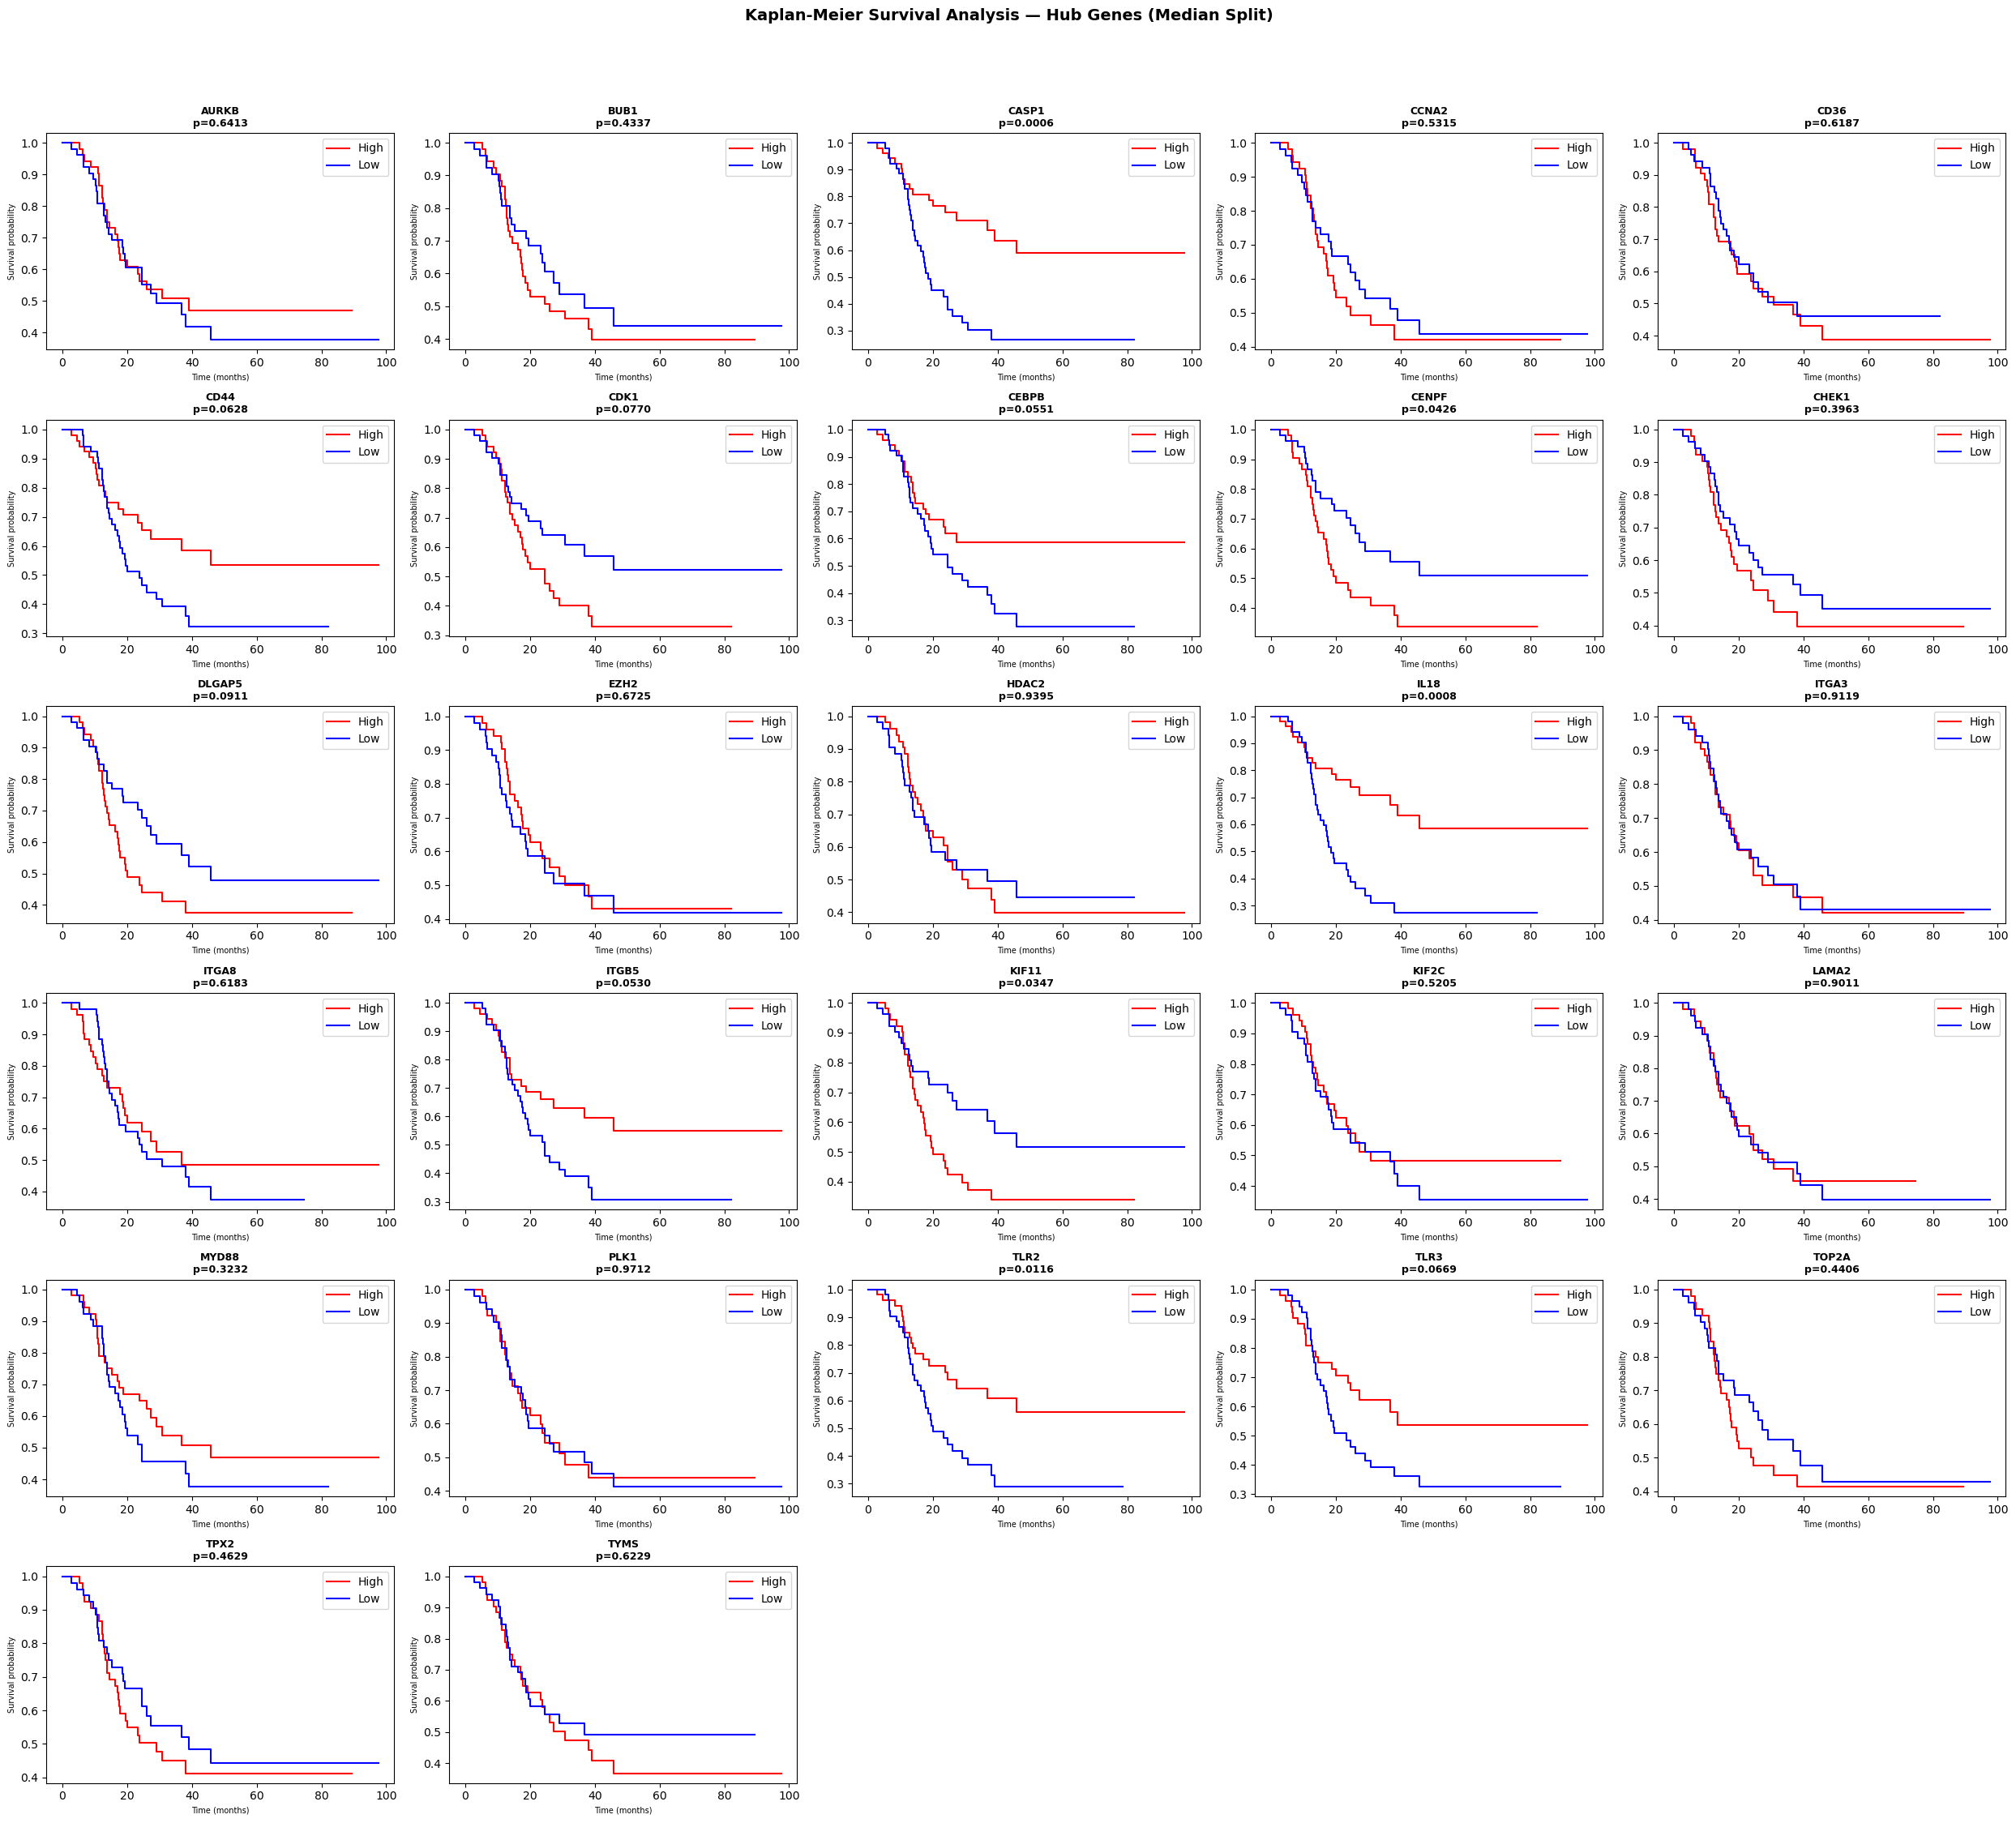

      Gene  P_value Significant
2    CASP1   0.0006         Yes
13    IL18   0.0008         Yes
22    TLR2   0.0116         Yes
17   KIF11   0.0347         Yes
8    CENPF   0.0426         Yes
16   ITGB5   0.0530          No
7    CEBPB   0.0551          No
5     CD44   0.0628          No
23    TLR3   0.0669          No
6     CDK1   0.0770          No
10  DLGAP5   0.0911          No
20   MYD88   0.3232          No
9    CHEK1   0.3963          No
1     BUB1   0.4337          No
24   TOP2A   0.4406          No
25    TPX2   0.4629          No
18   KIF2C   0.5205          No
3    CCNA2   0.5315          No
15   ITGA8   0.6183          No
4     CD36   0.6187          No
26    TYMS   0.6229          No
0    AURKB   0.6413          No
11    EZH2   0.6725          No
19   LAMA2   0.9011          No
14   ITGA3   0.9119          No
12   HDAC2   0.9395          No
21    PLK1   0.9712          No


In [61]:
fig, axes = plt.subplots(6, 5, figsize=(25, 22))
axes = axes.flatten()

km_results = []

for i, gene in enumerate(sorted(s1e_tumor.index)):
    ax = axes[i]
    
    # Median split
    median_val = merged_df[gene].median()
    high = merged_df[merged_df[gene] >= median_val]
    low  = merged_df[merged_df[gene] <  median_val]
    
    # Log-rank test
    result = logrank_test(high['time'], low['time'],
                          event_observed_A=high['event'],
                          event_observed_B=low['event'])
    pval = result.p_value
    
    # KM curves
    kmf_high = KaplanMeierFitter()
    kmf_low  = KaplanMeierFitter()
    kmf_high.fit(high['time'], event_observed=high['event'], label='High')
    kmf_low.fit(low['time'],  event_observed=low['event'],  label='Low')
    
    kmf_high.plot_survival_function(ax=ax, color='red',  ci_show=False)
    kmf_low.plot_survival_function(ax=ax, color='blue', ci_show=False)
    
    ax.set_title(f'{gene}\np={pval:.4f}', fontsize=9, fontweight='bold')
    ax.set_xlabel('Time (months)', fontsize=7)
    ax.set_ylabel('Survival probability', fontsize=7)
    
    km_results.append({'Gene': gene, 'P_value': round(pval, 4),
                       'Significant': 'Yes' if pval < 0.05 else 'No'})

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Kaplan-Meier Survival Analysis — Hub Genes (Median Split)', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.savefig('./figures/km_plots_all_hub_genes.png', dpi=300, bbox_inches='tight')
plt.show()

km_df = pd.DataFrame(km_results).sort_values('P_value')
print(km_df.to_string())

In [63]:
cluster_assignment = {
    'AURKB': 'Cluster1', 'BUB1': 'Cluster1', 'CCNA2': 'Cluster1',
    'CDK1': 'Cluster1', 'CENPF': 'Cluster1', 'CHEK1': 'Cluster1',
    'DLGAP5': 'Cluster1', 'KIF11': 'Cluster1', 'KIF2C': 'Cluster1',
    'PLK1': 'Cluster1', 'TOP2A': 'Cluster1', 'TPX2': 'Cluster1', 'TYMS': 'Cluster1',
    'CASP1': 'Cluster2', 'CD36': 'Cluster2', 'IL18': 'Cluster2',
    'MYD88': 'Cluster2', 'TLR2': 'Cluster2', 'TLR3': 'Cluster2',
    'CEBPB': 'Cluster3', 'EZH2': 'Cluster3', 'HDAC2': 'Cluster3',
    'CD44': 'Cluster4', 'ITGA3': 'Cluster4', 'ITGA8': 'Cluster4',
    'ITGB5': 'Cluster4', 'LAMA2': 'Cluster4'
}

km_df['Cluster'] = km_df['Gene'].map(cluster_assignment)
print(km_df.sort_values(['Cluster', 'P_value']).to_string())

      Gene  P_value Significant   Cluster
17   KIF11   0.0347         Yes  Cluster1
8    CENPF   0.0426         Yes  Cluster1
6     CDK1   0.0770          No  Cluster1
10  DLGAP5   0.0911          No  Cluster1
9    CHEK1   0.3963          No  Cluster1
1     BUB1   0.4337          No  Cluster1
24   TOP2A   0.4406          No  Cluster1
25    TPX2   0.4629          No  Cluster1
18   KIF2C   0.5205          No  Cluster1
3    CCNA2   0.5315          No  Cluster1
26    TYMS   0.6229          No  Cluster1
0    AURKB   0.6413          No  Cluster1
21    PLK1   0.9712          No  Cluster1
2    CASP1   0.0006         Yes  Cluster2
13    IL18   0.0008         Yes  Cluster2
22    TLR2   0.0116         Yes  Cluster2
23    TLR3   0.0669          No  Cluster2
20   MYD88   0.3232          No  Cluster2
4     CD36   0.6187          No  Cluster2
7    CEBPB   0.0551          No  Cluster3
11    EZH2   0.6725          No  Cluster3
12   HDAC2   0.9395          No  Cluster3
16   ITGB5   0.0530          No  C

In [83]:
from lifelines import CoxPHFitter

hr_results = []

for gene in sorted(s1e_tumor.index):
    median_val = merged_df[gene].median()
    temp_df = merged_df[['time', 'event', gene]].copy()
    temp_df['group'] = (temp_df[gene] >= median_val).astype(int)  # 1=high, 0=low
    
    cph = CoxPHFitter()
    cph.fit(temp_df[['time', 'event', 'group']], duration_col='time', event_col='event')
    
    hr = cph.hazard_ratios_['group']
    ci_low = cph.confidence_intervals_.loc['group', '95% lower-bound']
    ci_high = cph.confidence_intervals_.loc['group', '95% upper-bound']
    pval = cph.summary.loc['group', 'p']
    
    hr_results.append({
        'Gene': gene,
        'HR': round(hr, 3),
        'CI_low': round(ci_low, 3),
        'CI_high': round(ci_high, 3),
        'P_value': round(pval, 4),
        'Cluster': cluster_assignment[gene]
    })

hr_df = pd.DataFrame(hr_results).sort_values(['Cluster', 'P_value'])
print(hr_df.to_string())

      Gene     HR  CI_low  CI_high  P_value   Cluster
17   KIF11  1.814   0.035    1.156   0.0373  Cluster1
8    CENPF  1.763   0.012    1.122   0.0454  Cluster1
6     CDK1  1.642  -0.059    1.051   0.0798  Cluster1
10  DLGAP5  1.602  -0.080    1.023   0.0941  Cluster1
9    CHEK1  1.266  -0.311    0.782   0.3974  Cluster1
1     BUB1  1.244  -0.330    0.767   0.4347  Cluster1
24   TOP2A  1.240  -0.331    0.761   0.4406  Cluster1
25    TPX2  1.226  -0.342    0.750   0.4638  Cluster1
18   KIF2C  0.836  -0.724    0.367   0.5211  Cluster1
3    CCNA2  1.190  -0.372    0.720   0.5321  Cluster1
26    TYMS  1.147  -0.409    0.682   0.6232  Cluster1
0    AURKB  0.879  -0.673    0.415   0.6427  Cluster1
21    PLK1  0.990  -0.555    0.535   0.9700  Cluster1
2    CASP1  0.372  -1.575   -0.405   0.0009  Cluster2
13    IL18  0.382  -1.547   -0.379   0.0012  Cluster2
22    TLR2  0.490  -1.280   -0.147   0.0135  Cluster2
23    TLR3  0.596  -1.078    0.042   0.0698  Cluster2
20   MYD88  0.760  -0.822   

In [85]:
# Keep only significant (p<0.05) and borderline (p<0.10)
hr_filtered = hr_df[hr_df['P_value'] < 0.10].copy()

# Add significance label
hr_filtered['Significance'] = hr_filtered['P_value'].apply(
    lambda p: 'Significant' if p < 0.05 else 'Borderline'
)

# Format CI as a single string for readability
hr_filtered['95% CI'] = hr_filtered.apply(
    lambda row: f"({row['CI_low']}, {row['CI_high']})", axis=1
)

hr_filtered = hr_filtered[['Cluster', 'Gene', 'HR', '95% CI', 'P_value', 'Significance']]
print(hr_filtered.sort_values(['Cluster', 'P_value']).to_string())

     Cluster    Gene     HR            95% CI  P_value Significance
17  Cluster1   KIF11  1.814    (0.035, 1.156)   0.0373  Significant
8   Cluster1   CENPF  1.763    (0.012, 1.122)   0.0454  Significant
6   Cluster1    CDK1  1.642   (-0.059, 1.051)   0.0798   Borderline
10  Cluster1  DLGAP5  1.602    (-0.08, 1.023)   0.0941   Borderline
2   Cluster2   CASP1  0.372  (-1.575, -0.405)   0.0009  Significant
13  Cluster2    IL18  0.382  (-1.547, -0.379)   0.0012  Significant
22  Cluster2    TLR2  0.490   (-1.28, -0.147)   0.0135  Significant
23  Cluster2    TLR3  0.596   (-1.078, 0.042)   0.0698   Borderline
7   Cluster3   CEBPB  0.582     (-1.1, 0.019)   0.0583   Borderline
16  Cluster4   ITGB5  0.579   (-1.107, 0.014)   0.0560   Borderline
5   Cluster4    CD44  0.591   (-1.085, 0.034)   0.0659   Borderline


In [89]:
import numpy as np

hr_filtered = hr_df[hr_df['P_value'] < 0.10].copy()

hr_filtered['HR_CI_low'] = np.exp(hr_filtered['CI_low']).round(3)
hr_filtered['HR_CI_high'] = np.exp(hr_filtered['CI_high']).round(3)
hr_filtered['95% CI (HR scale)'] = hr_filtered.apply(
    lambda row: f"({row['HR_CI_low']}, {row['HR_CI_high']})", axis=1
)
hr_filtered['Significance'] = hr_filtered['P_value'].apply(
    lambda p: 'Significant' if p < 0.05 else 'Borderline'
)

final_table = hr_filtered[['Cluster', 'Gene', 'HR', '95% CI (HR scale)', 'P_value', 'Significance']]
print(final_table.sort_values(['Cluster', 'P_value']).to_string())

     Cluster    Gene     HR 95% CI (HR scale)  P_value Significance
17  Cluster1   KIF11  1.814    (1.036, 3.177)   0.0373  Significant
8   Cluster1   CENPF  1.763    (1.012, 3.071)   0.0454  Significant
6   Cluster1    CDK1  1.642    (0.943, 2.861)   0.0798   Borderline
10  Cluster1  DLGAP5  1.602    (0.923, 2.782)   0.0941   Borderline
2   Cluster2   CASP1  0.372    (0.207, 0.667)   0.0009  Significant
13  Cluster2    IL18  0.382    (0.213, 0.685)   0.0012  Significant
22  Cluster2    TLR2  0.490    (0.278, 0.863)   0.0135  Significant
23  Cluster2    TLR3  0.596     (0.34, 1.043)   0.0698   Borderline
7   Cluster3   CEBPB  0.582    (0.333, 1.019)   0.0583   Borderline
16  Cluster4   ITGB5  0.579    (0.331, 1.014)   0.0560   Borderline
5   Cluster4    CD44  0.591    (0.338, 1.035)   0.0659   Borderline


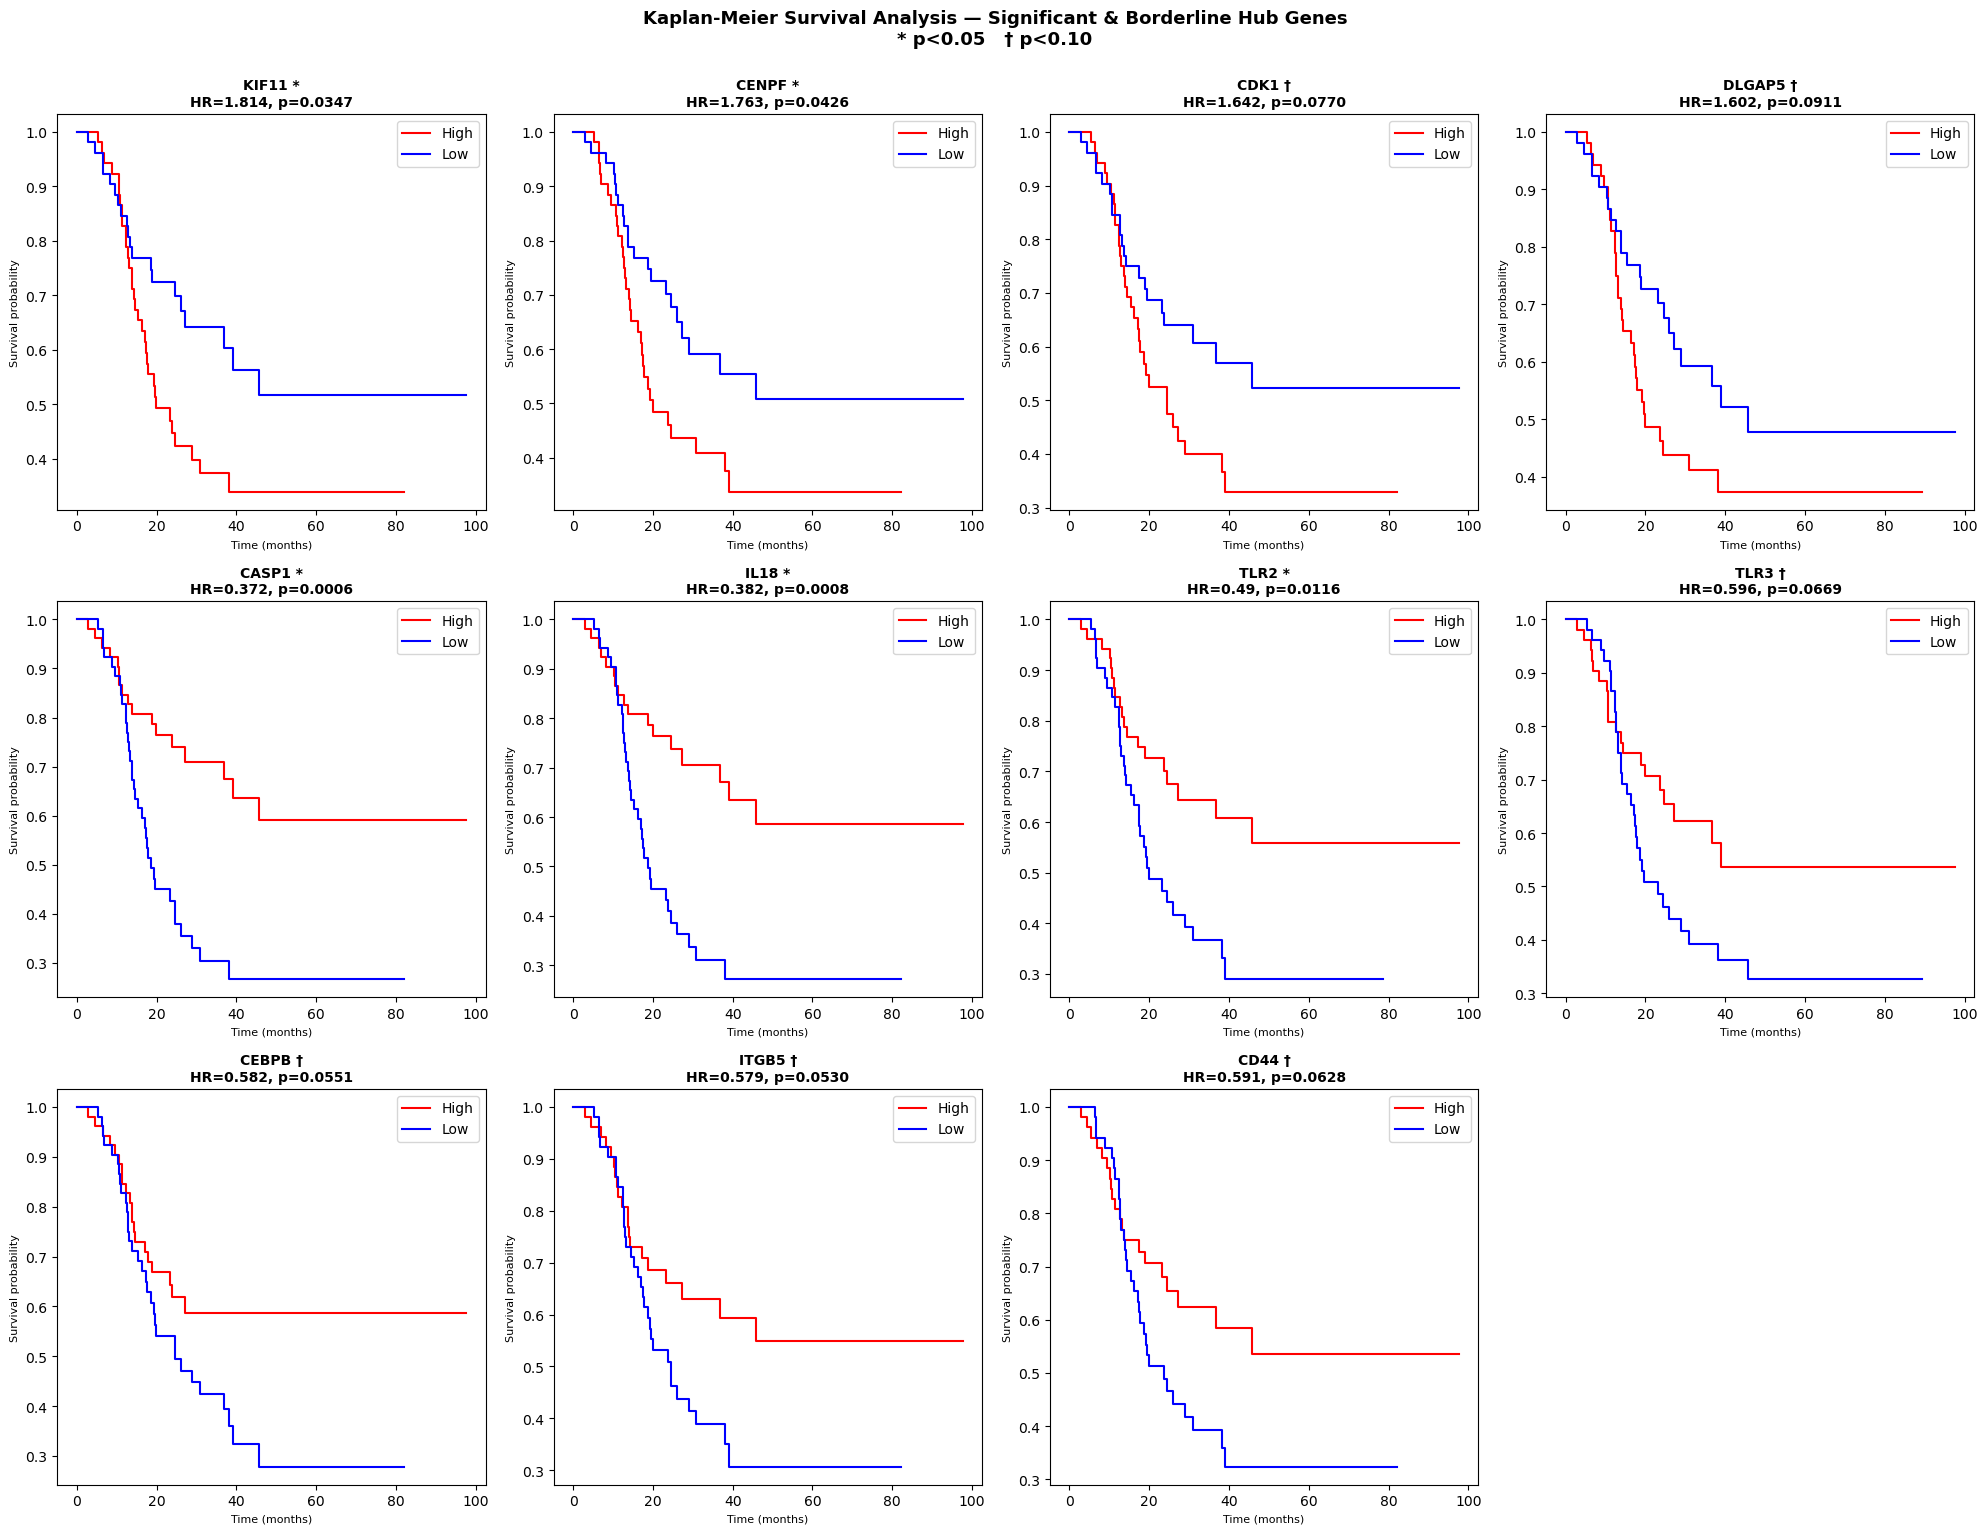

In [91]:
sig_borderline_genes = final_table['Gene'].tolist()

fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()

for i, gene in enumerate(sig_borderline_genes):
    ax = axes[i]
    
    median_val = merged_df[gene].median()
    high = merged_df[merged_df[gene] >= median_val]
    low  = merged_df[merged_df[gene] <  median_val]
    
    result = logrank_test(high['time'], low['time'],
                          event_observed_A=high['event'],
                          event_observed_B=low['event'])
    pval = result.p_value
    
    kmf_high = KaplanMeierFitter()
    kmf_low  = KaplanMeierFitter()
    kmf_high.fit(high['time'], event_observed=high['event'], label='High')
    kmf_low.fit(low['time'],  event_observed=low['event'],  label='Low')
    
    kmf_high.plot_survival_function(ax=ax, color='red',  ci_show=False)
    kmf_low.plot_survival_function(ax=ax, color='blue', ci_show=False)
    
    row = final_table[final_table['Gene'] == gene].iloc[0]
    sig_label = '*' if row['Significance'] == 'Significant' else '†'
    
    ax.set_title(f"{gene} {sig_label}\nHR={row['HR']}, p={pval:.4f}", 
                 fontsize=10, fontweight='bold')
    ax.set_xlabel('Time (months)', fontsize=8)
    ax.set_ylabel('Survival probability', fontsize=8)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Kaplan-Meier Survival Analysis — Significant & Borderline Hub Genes\n* p<0.05   † p<0.10', 
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.savefig('./figures/km_plots_significant.png', dpi=300, bbox_inches='tight')
plt.show()

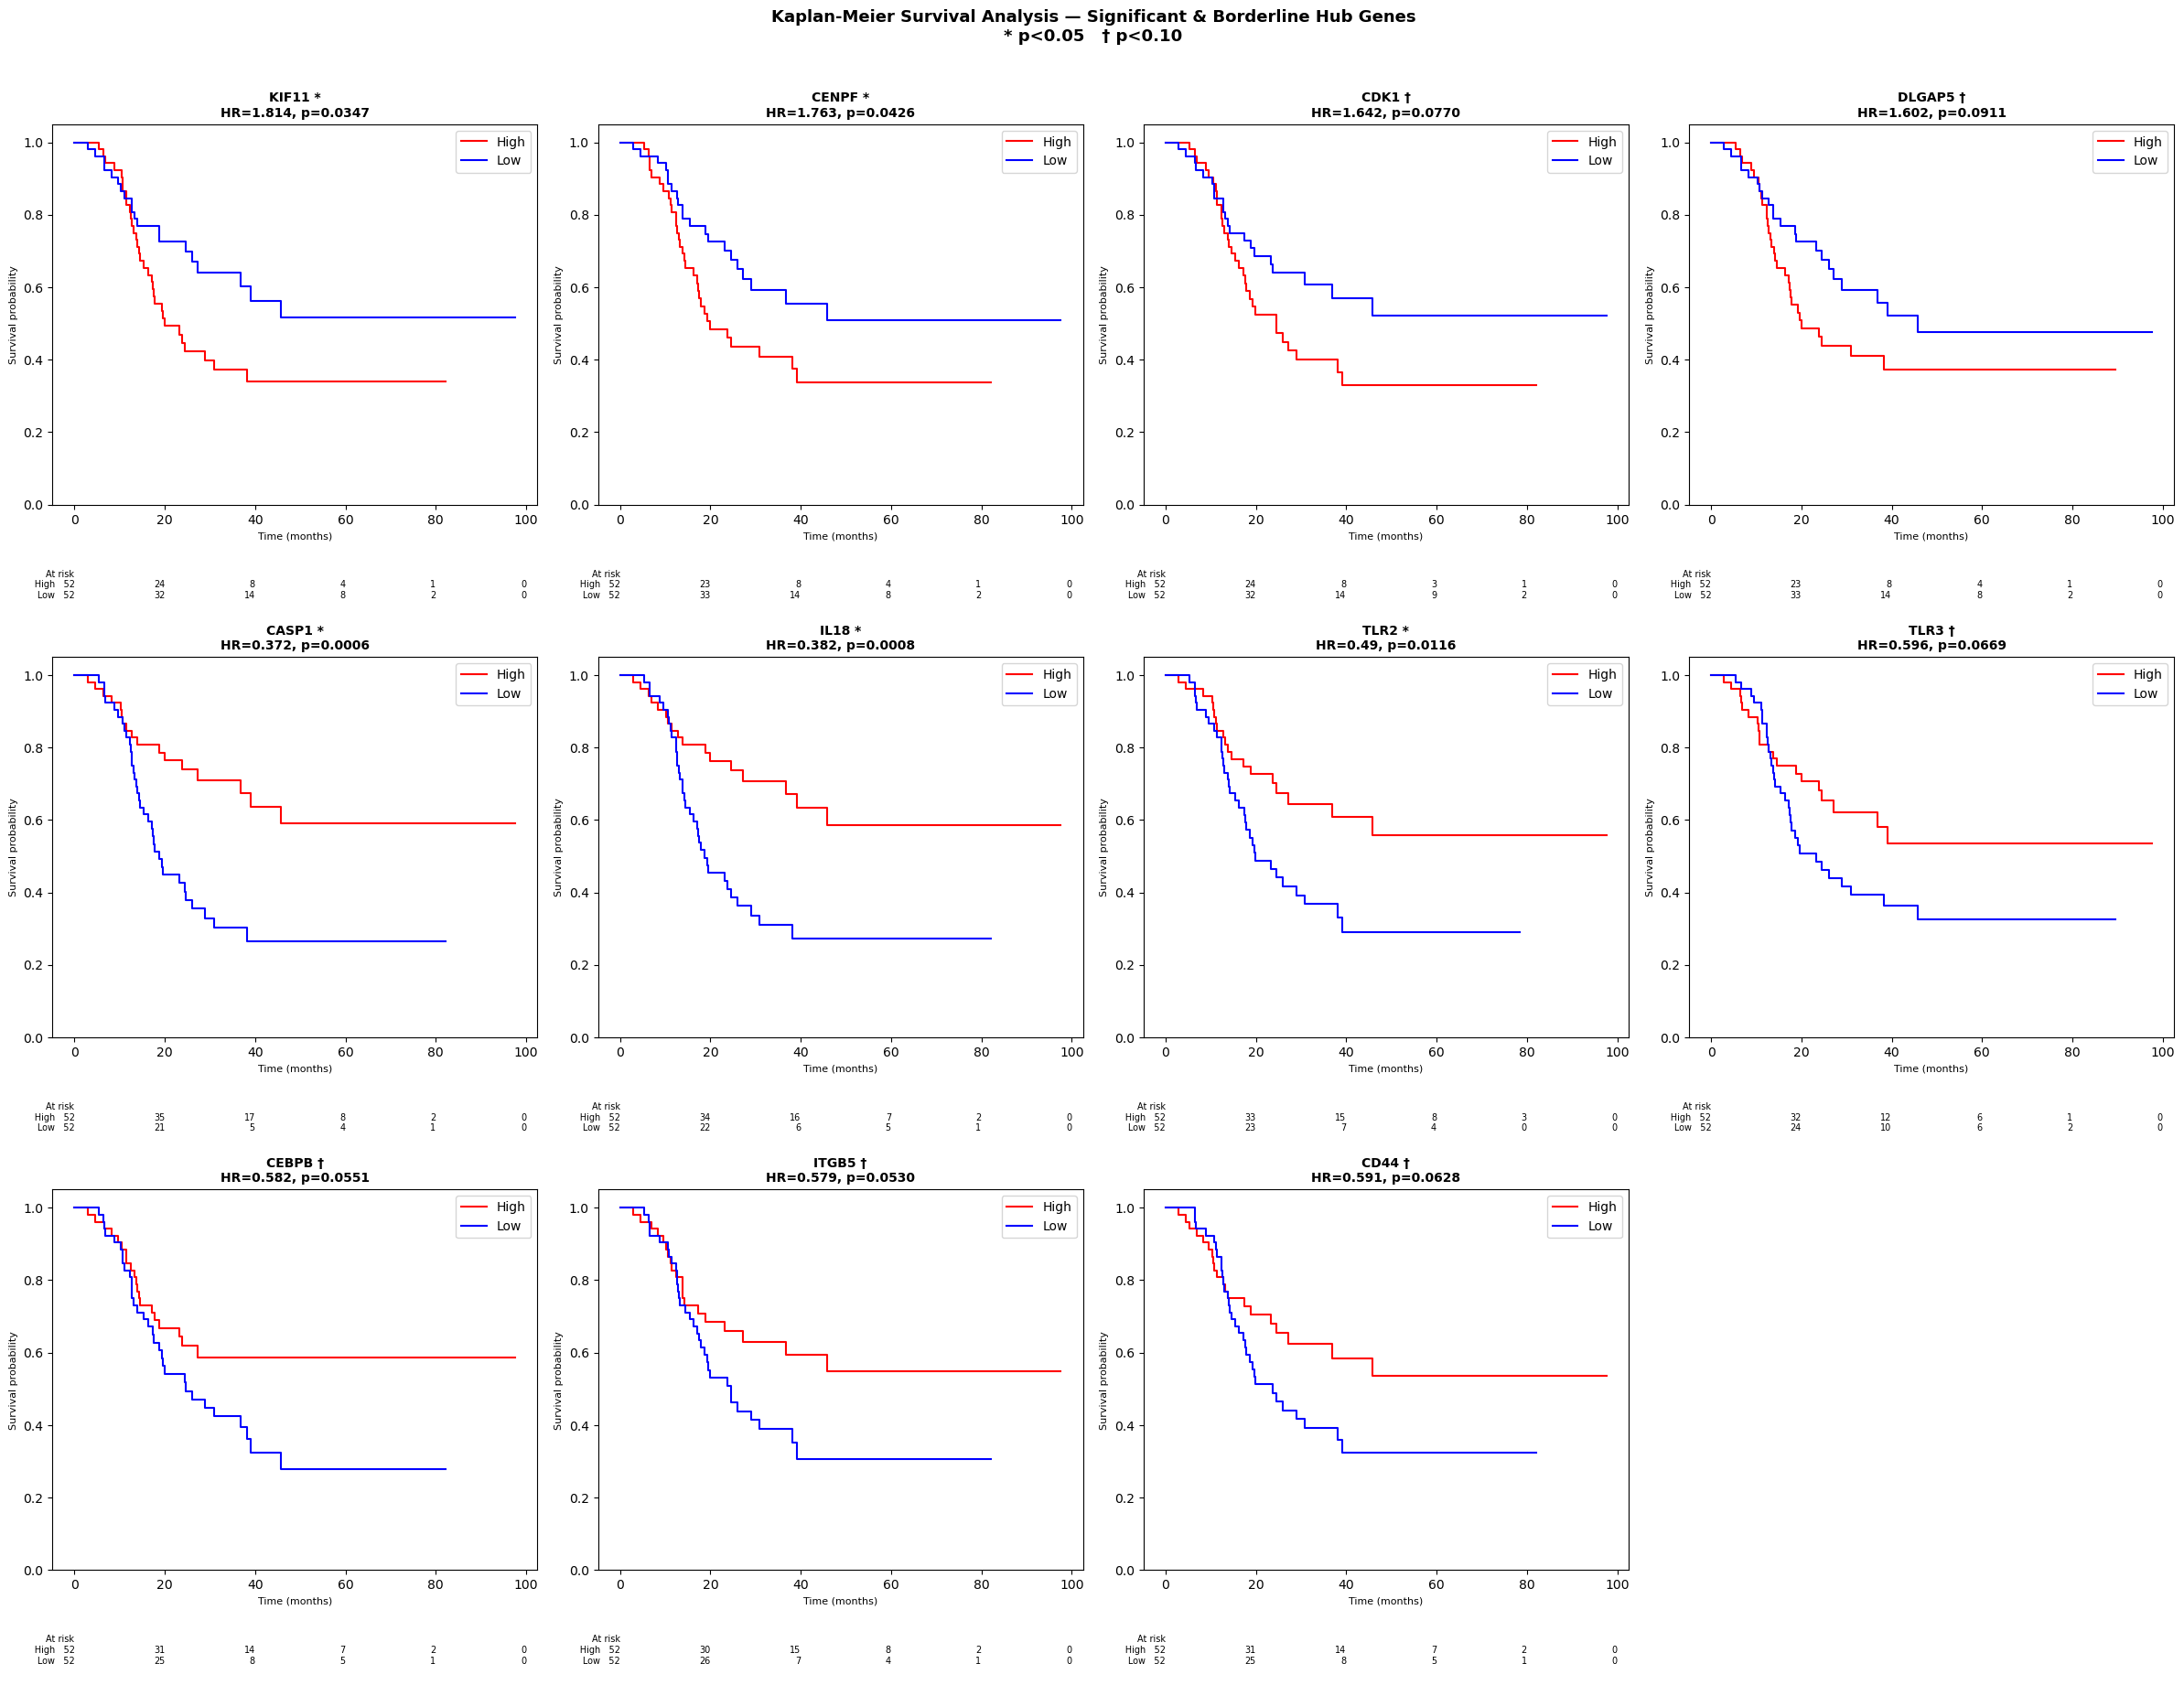

In [129]:
from lifelines.plotting import add_at_risk_counts

fig, axes = plt.subplots(3, 4, figsize=(24, 18))
axes = axes.flatten()

for i, gene in enumerate(sig_borderline_genes):
    ax = axes[i]
    
    median_val = merged_df[gene].median()
    high = merged_df[merged_df[gene] >= median_val]
    low  = merged_df[merged_df[gene] <  median_val]
    
    result = logrank_test(high['time'], low['time'],
                          event_observed_A=high['event'],
                          event_observed_B=low['event'])
    pval = result.p_value
    
    kmf_high = KaplanMeierFitter()
    kmf_low  = KaplanMeierFitter()
    kmf_high.fit(high['time'], event_observed=high['event'], label='High')
    kmf_low.fit(low['time'],  event_observed=low['event'],  label='Low')
    
    kmf_high.plot_survival_function(ax=ax, color='red',  ci_show=False)
    kmf_low.plot_survival_function(ax=ax, color='blue', ci_show=False)
    
    # Fix y-axis to start at 0
    ax.set_ylim(0, 1.05)
    
    # Add number at risk table
    add_at_risk_counts(kmf_high, kmf_low, ax=ax, fontsize=7, 
                       rows_to_show=['At risk'])
    
    row = final_table[final_table['Gene'] == gene].iloc[0]
    sig_label = '*' if row['Significance'] == 'Significant' else '†'
    
    ax.set_title(f"{gene} {sig_label}\nHR={row['HR']}, p={pval:.4f}", 
                 fontsize=10, fontweight='bold')
    ax.set_xlabel('Time (months)', fontsize=8)
    ax.set_ylabel('Survival probability', fontsize=8)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Kaplan-Meier Survival Analysis — Significant & Borderline Hub Genes\n* p<0.05   † p<0.10', 
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.savefig('./figures/km_plots_significant.png', dpi=300, bbox_inches='tight')
plt.show()

In [93]:
final_table.to_csv('./results/proteomics/km_survival_hr_results.csv', index=False)
print("Saved.")

Saved.


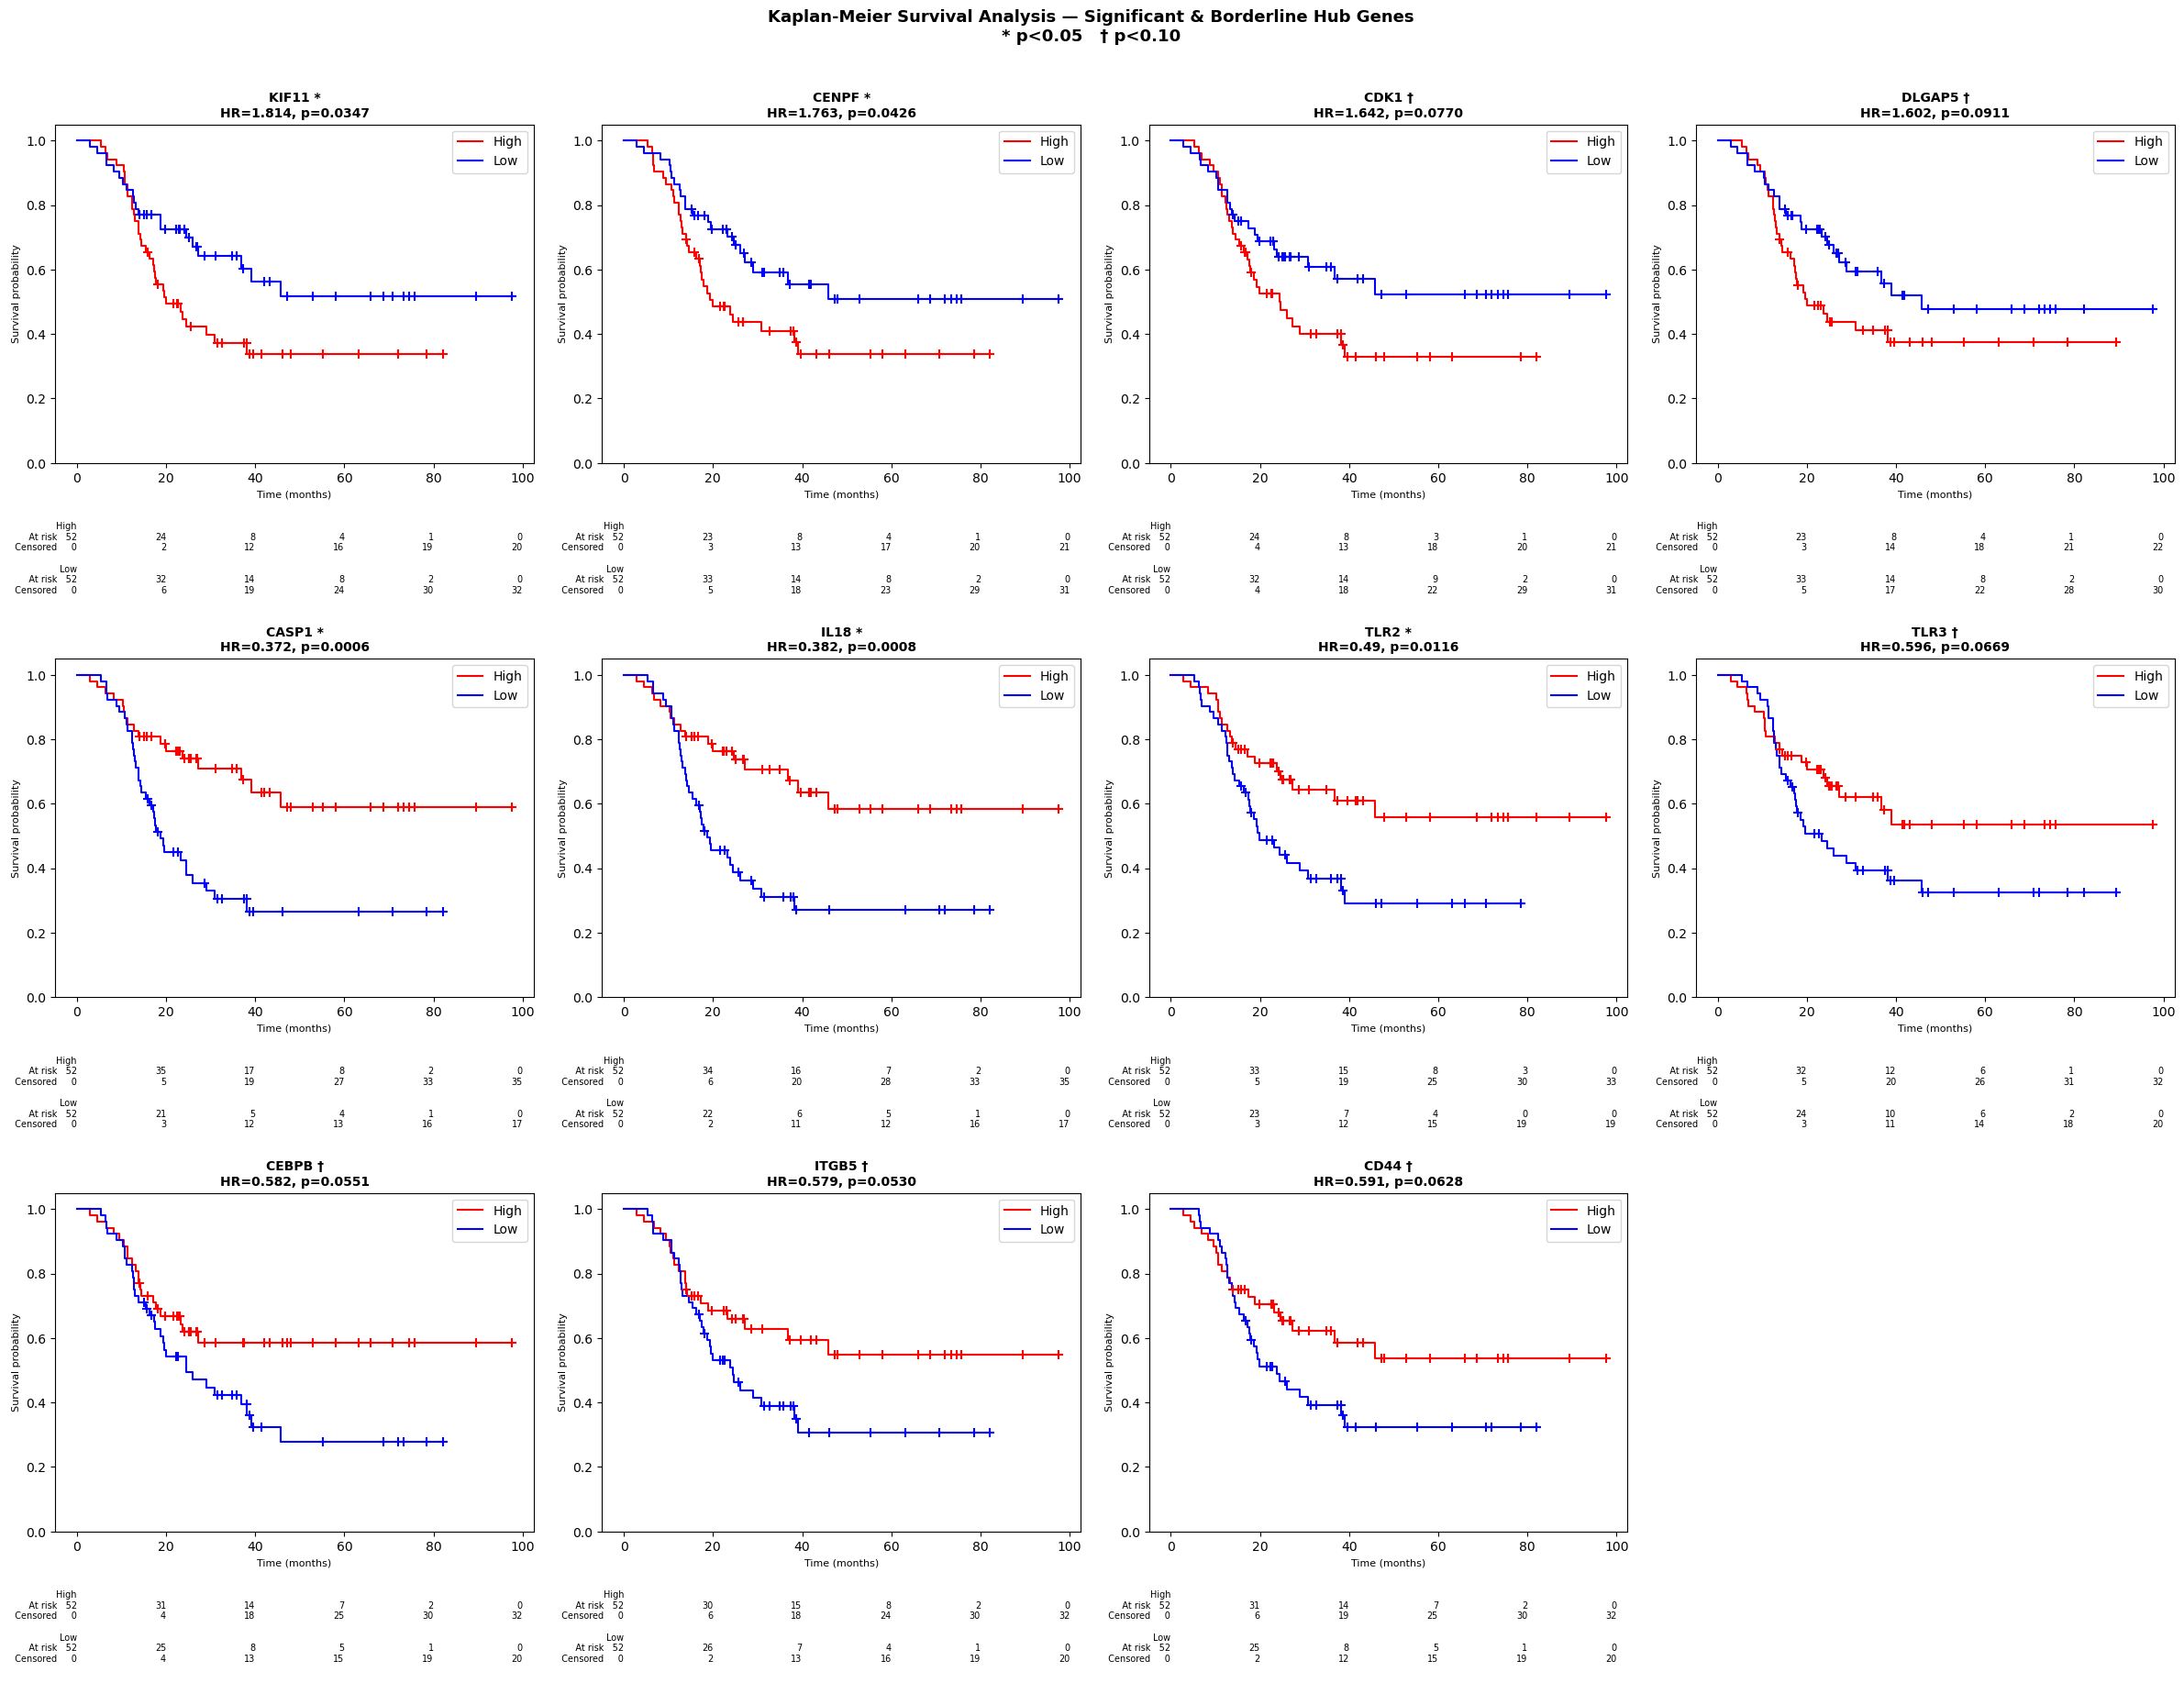

In [103]:
from lifelines.plotting import add_at_risk_counts

fig, axes = plt.subplots(3, 4, figsize=(24, 18))
axes = axes.flatten()

for i, gene in enumerate(sig_borderline_genes):
    ax = axes[i]
    
    median_val = merged_df[gene].median()
    high = merged_df[merged_df[gene] >= median_val]
    low  = merged_df[merged_df[gene] <  median_val]
    
    result = logrank_test(high['time'], low['time'],
                          event_observed_A=high['event'],
                          event_observed_B=low['event'])
    pval = result.p_value
    
    kmf_high = KaplanMeierFitter()
    kmf_low  = KaplanMeierFitter()
    kmf_high.fit(high['time'], event_observed=high['event'], label='High')
    kmf_low.fit(low['time'],  event_observed=low['event'],  label='Low')
    
    kmf_high.plot_survival_function(ax=ax, color='red', ci_show=False)
    kmf_low.plot_survival_function(ax=ax, color='blue', ci_show=False)
    
    # Add censored tick marks manually
    high_censored = high[high['event'] == 0]
    low_censored = low[low['event'] == 0]
    
    # Get survival probability at censored timepoints
    for t in high_censored['time']:
        p = kmf_high.survival_function_at_times(t).values[0]
        ax.scatter(t, p, marker='+', color='red', s=50, zorder=5)
    for t in low_censored['time']:
        p = kmf_low.survival_function_at_times(t).values[0]
        ax.scatter(t, p, marker='+', color='blue', s=50, zorder=5)
    
    ax.set_ylim(0, 1.05)
    
    add_at_risk_counts(kmf_high, kmf_low, ax=ax, fontsize=7,
                       rows_to_show=['At risk', 'Censored'])
    
    row = final_table[final_table['Gene'] == gene].iloc[0]
    sig_label = '*' if row['Significance'] == 'Significant' else '†'
    
    ax.set_title(f"{gene} {sig_label}\nHR={row['HR']}, p={pval:.4f}",
                 fontsize=10, fontweight='bold')
    ax.set_xlabel('Time (months)', fontsize=8)
    ax.set_ylabel('Survival probability', fontsize=8)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Kaplan-Meier Survival Analysis — Significant & Borderline Hub Genes\n* p<0.05   † p<0.10',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.savefig('./figures/km_plots_significant.png', dpi=300, bbox_inches='tight')
plt.show()